In [ ]:
from google.colab import files

uploaded = files.upload()

Saving logistics_dataset.csv to logistics_dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("logistics_dataset.csv")

print("Shape:", df.shape)

df.head()

Shape: (200, 7)


,Shipment_ID,Delivery_Partner,Region,Promised_Date,Actual_Date,Delivery_Cost,Customer_Rating
0,S0001,QuickShip,East,2026-08-09,2026-08-11,261.23,3.5
1,S0002,EcoDelivery,North,2026-08-30,2026-09-01,261.08,3.6
2,S0003,SafeExpress,North,2026-08-17,2026-08-19,414.82,3.7
3,S0004,SafeExpress,West,2026-08-17,2026-08-19,412.82,3.8
4,S0005,FastTrack,East,2026-08-30,2026-08-30,279.85,4.4


In [ ]:
df.isnull().sum()

,0
Shipment_ID,0
Delivery_Partner,0
Region,0
Promised_Date,0
Actual_Date,0
Delivery_Cost,0
Customer_Rating,0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(
    "Duplicate Shipment IDs:",
    df["Shipment_ID"].duplicated().sum()
)

Duplicate Shipment IDs: 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Shipment_ID       200 non-null    object 
 1   Delivery_Partner  200 non-null    object 
 2   Region            200 non-null    object 
 3   Promised_Date     200 non-null    object 
 4   Actual_Date       200 non-null    object 
 5   Delivery_Cost     200 non-null    float64
 6   Customer_Rating   200 non-null    float64
dtypes: float64(2), object(5)
memory usage: 11.1+ KB


In [ ]:
df["Promised_Date"] = pd.to_datetime(
    df["Promised_Date"]
)

df["Actual_Date"] = pd.to_datetime(
    df["Actual_Date"]
)

In [ ]:
print(df["Delivery_Cost"].describe())
print(df["Customer_Rating"].describe())

count    200.000000
mean     294.591700
std       55.321823
min      150.000000
25%      259.280000
50%      302.130000
75%      328.837500
max      433.250000
Name: Delivery_Cost, dtype: float64
count    200.000000
mean       3.489000
std        0.793427
min        1.600000
25%        2.900000
50%        3.500000
75%        4.100000
max        5.000000
Name: Customer_Rating, dtype: float64


In [ ]:
df["Delivery_Delay"] = (
    df["Actual_Date"] -
    df["Promised_Date"]
).dt.days

In [ ]:
df["On_Time"] = (
    df["Delivery_Delay"] <= 0
).astype(int)

In [ ]:
df.head()

,Shipment_ID,Delivery_Partner,Region,Promised_Date,Actual_Date,Delivery_Cost,Customer_Rating,Delivery_Delay,On_Time
0,S0001,QuickShip,East,2026-08-09,2026-08-11,261.23,3.5,2,0
1,S0002,EcoDelivery,North,2026-08-30,2026-09-01,261.08,3.6,2,0
2,S0003,SafeExpress,North,2026-08-17,2026-08-19,414.82,3.7,2,0
3,S0004,SafeExpress,West,2026-08-17,2026-08-19,412.82,3.8,2,0
4,S0005,FastTrack,East,2026-08-30,2026-08-30,279.85,4.4,0,1


In [ ]:
overall_on_time = df["On_Time"].mean() * 100

print(
    f"Overall On-Time Delivery: {overall_on_time:.2f}%"
)

Overall On-Time Delivery: 30.50%


In [ ]:
partner_ontime = (
    df.groupby("Delivery_Partner")["On_Time"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(partner_ontime)

Delivery_Partner
FastTrack      46.428571
SafeExpress    25.531915
QuickShip      23.913043
EcoDelivery    23.529412
Name: On_Time, dtype: float64


In [ ]:
partner_summary = df.groupby(
    "Delivery_Partner"
).agg(
    On_Time_Percentage=("On_Time", "mean"),
    Average_Cost=("Delivery_Cost", "mean"),
    Average_Rating=("Customer_Rating", "mean"),
    Average_Delay=("Delivery_Delay", "mean"),
    Shipment_Count=("Shipment_ID", "count")
)

partner_summary["On_Time_Percentage"] *= 100

partner_summary

,On_Time_Percentage,Average_Cost,Average_Rating,Average_Delay,Shipment_Count
Delivery_Partner,,,,,
EcoDelivery,23.529412,241.469020,3.358824,2.215686,51
FastTrack,46.428571,313.183036,3.798214,0.892857,56
QuickShip,23.913043,278.401304,3.391304,1.956522,46
SafeExpress,25.531915,345.930000,3.357447,2.361702,47


In [ ]:
region_summary = df.groupby("Region").agg(
    On_Time_Percentage=("On_Time", "mean"),
    Average_Cost=("Delivery_Cost", "mean"),
    Average_Rating=("Customer_Rating", "mean"),
    Average_Delay=("Delivery_Delay", "mean")
)

region_summary["On_Time_Percentage"] *= 100

region_summary

,On_Time_Percentage,Average_Cost,Average_Rating,Average_Delay
Region,,,,
East,23.404255,304.140851,3.308511,2.234043
North,32.653061,298.915102,3.506122,1.775510
South,34.545455,280.656909,3.570909,1.690909
West,30.612245,296.750000,3.553061,1.612245


In [ ]:
partner_region = pd.pivot_table(
    df,
    values="On_Time",
    index="Delivery_Partner",
    columns="Region",
    aggfunc="mean"
) * 100

partner_region

Region,East,North,South,West
Delivery_Partner,,,,
EcoDelivery,15.384615,10.000000,35.294118,27.272727
FastTrack,46.666667,42.857143,55.555556,44.444444
QuickShip,0.000000,50.000000,27.777778,0.000000
SafeExpress,22.222222,23.076923,27.272727,28.571429


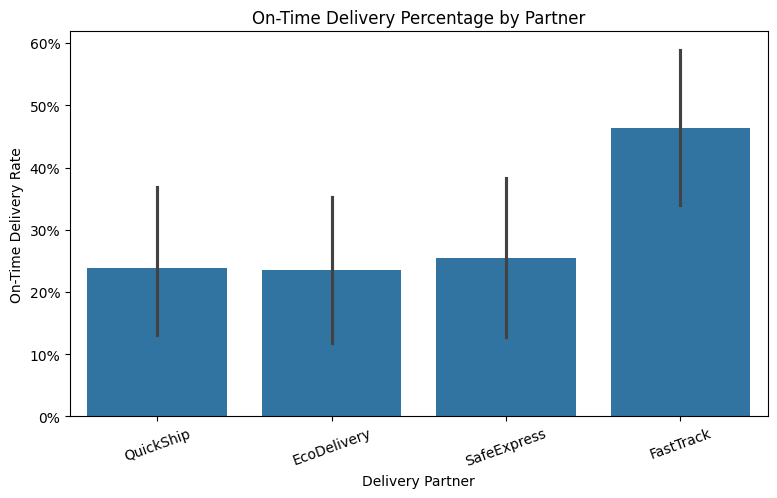

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Delivery_Partner",
    y="On_Time"
)

plt.title("On-Time Delivery Percentage by Partner")
plt.xlabel("Delivery Partner")
plt.ylabel("On-Time Delivery Rate")

plt.gca().yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.xticks(rotation=20)
plt.show()

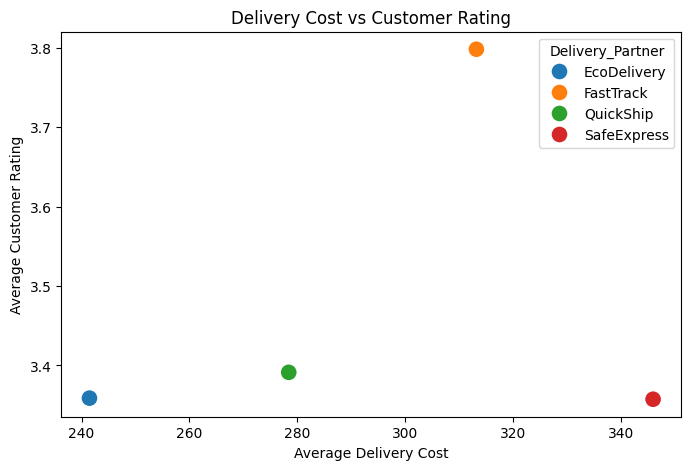

In [ ]:
partner_summary_plot = (
    df.groupby("Delivery_Partner")
    .agg(
        Delivery_Cost=("Delivery_Cost", "mean"),
        Customer_Rating=("Customer_Rating", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=partner_summary_plot,
    x="Delivery_Cost",
    y="Customer_Rating",
    hue="Delivery_Partner",
    s=150
)

plt.title("Delivery Cost vs Customer Rating")
plt.xlabel("Average Delivery Cost")
plt.ylabel("Average Customer Rating")

plt.show()

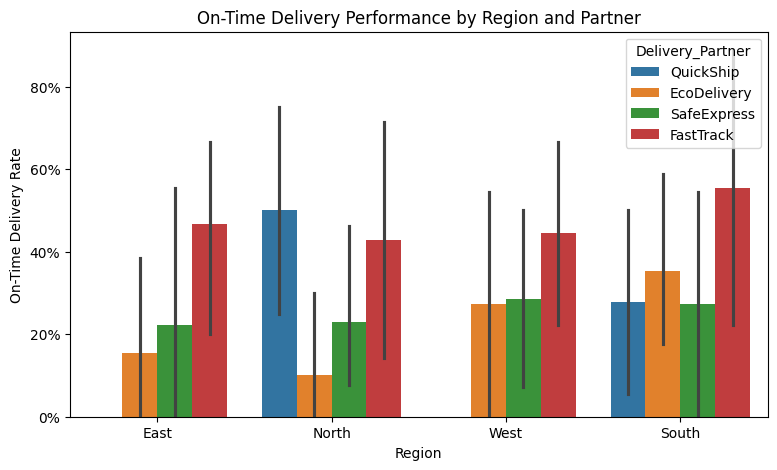

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Region",
    y="On_Time",
    hue="Delivery_Partner"
)

plt.title(
    "On-Time Delivery Performance by Region and Partner"
)

plt.ylabel("On-Time Delivery Rate")

plt.gca().yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.show()

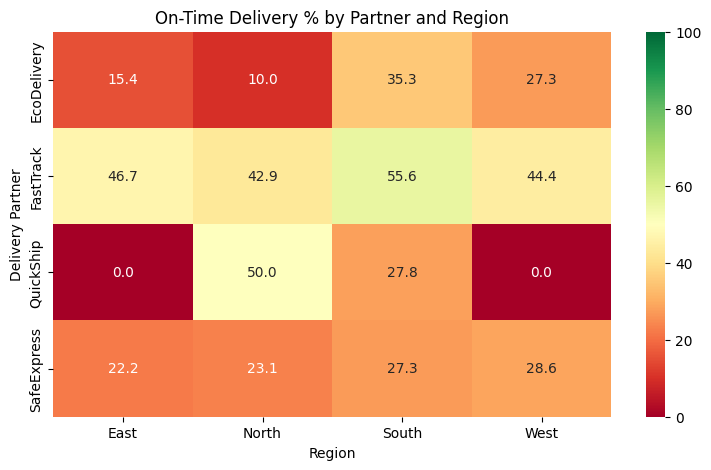

In [ ]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    partner_region,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100
)

plt.title(
    "On-Time Delivery % by Partner and Region"
)

plt.xlabel("Region")
plt.ylabel("Delivery Partner")

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model_df = df[
    [
        "Delivery_Partner",
        "Region",
        "Delivery_Cost",
        "Customer_Rating",
        "On_Time"
    ]
].copy()

model_df = pd.get_dummies(
    model_df,
    columns=[
        "Delivery_Partner",
        "Region"
    ],
    drop_first=True
)

In [ ]:
X = model_df.drop(
    "On_Time",
    axis=1
)

y = model_df["On_Time"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    accuracy
)

Accuracy: 0.875


In [ ]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.93      0.89      0.91        28
           1       0.77      0.83      0.80        12

    accuracy                           0.88        40
   macro avg       0.85      0.86      0.85        40
weighted avg       0.88      0.88      0.88        40



In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[25  3]
 [ 2 10]]


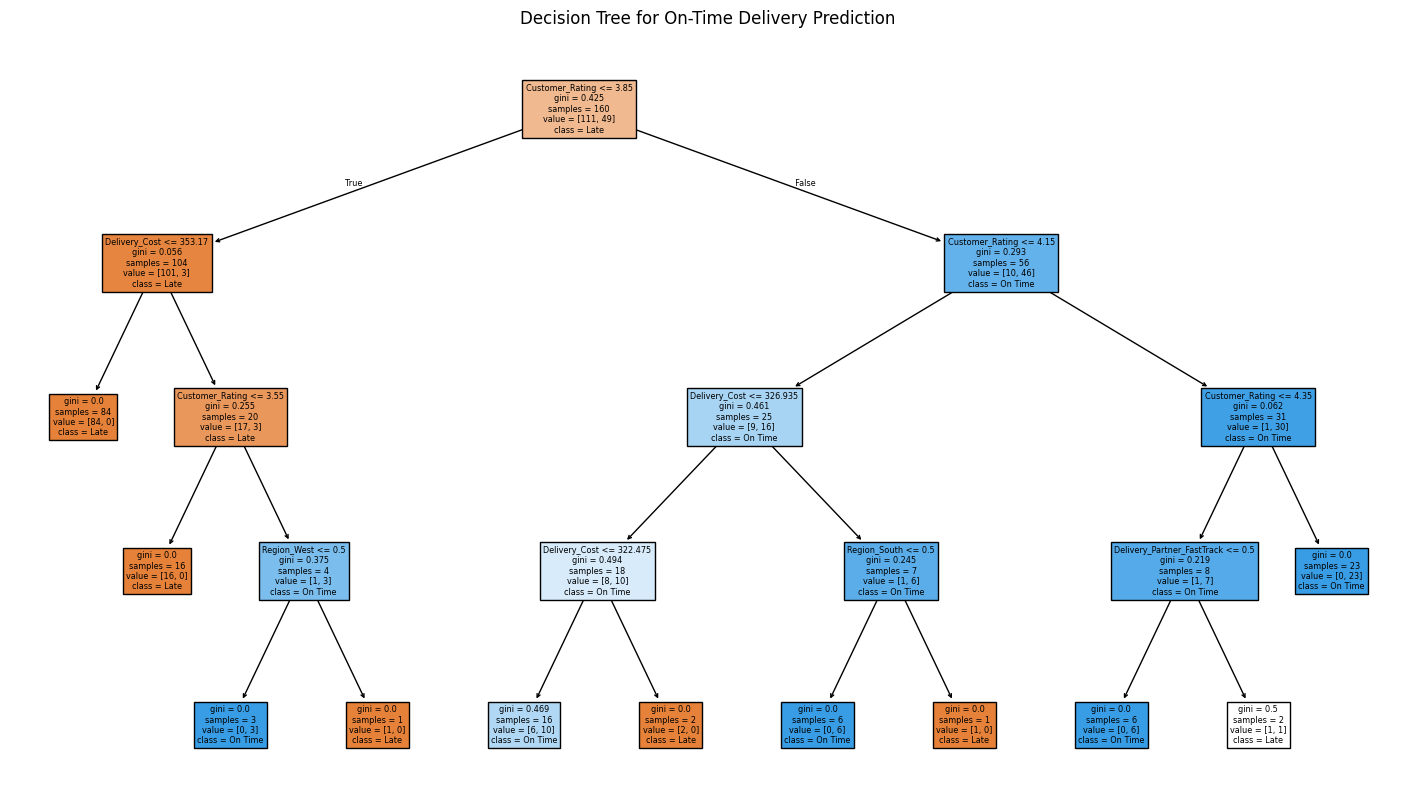

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Late", "On Time"],
    filled=True
)

plt.title("Decision Tree for On-Time Delivery Prediction")

plt.show()

KEY INSIGHTS :

1. On-time delivery percentage provides an important measure of operational
   performance, but it should be considered together with delivery cost and
   customer satisfaction.

2. The delivery partners show differences in their average on-time delivery
   rates, indicating that operational performance is not identical across
   partners.

3. Delivery costs vary between partners, demonstrating that a lower-cost
   partner should not automatically be considered the most suitable option
   without considering service quality.

4. Customer ratings provide an additional perspective on delivery service
   quality. Higher customer satisfaction can be associated with more
   reliable delivery experiences.

5. Regional analysis shows that delivery performance can vary across regions.
   A partner with reasonable overall performance may still have weaker
   performance in particular regions.

6. The partner-versus-region analysis helps identify whether a delivery
   partner performs consistently across the service area or whether its
   performance depends on the region.

7. The Decision Tree model achieved an accuracy of [INSERT ACCURACY] on the
   test dataset. The model demonstrates how shipment-related characteristics
   can be used to classify whether a delivery is likely to be on time.

ACTION PLAN :

1. Evaluate delivery partners using multiple metrics including on-time
   delivery percentage, average delivery cost, customer rating, average
   delay, and regional consistency.

2. Avoid selecting a delivery partner based only on the lowest cost or the
   highest overall on-time delivery rate.

3. Monitor partner performance separately for each region because overall
   averages may hide regional weaknesses.

4. Investigate partners that perform well overall but show significantly
   lower on-time delivery rates in particular regions.

5. Track customer ratings alongside delivery performance to identify
   situations where operational performance and customer satisfaction differ.

6. Review high-delay shipments and identify recurring operational patterns
   that could contribute to late deliveries.

7. Use the Decision Tree model as a supporting analytical tool to identify
   factors associated with on-time or delayed shipments.

8. Recalculate partner performance regularly as shipment volumes, regions,
   costs, and customer expectations change over time.

CONCLUSION :

This project analysed the performance of multiple third-party delivery
partners using shipment dates, delivery cost, customer ratings, and regional
information.

The analysis demonstrated that delivery-partner performance cannot be
evaluated effectively using a single metric. On-time delivery provides an
important measure of reliability, while delivery cost indicates operational
expense and customer rating provides a service-quality perspective.

The regional analysis further showed the importance of examining partner
performance across different locations. A partner's overall performance can
hide variations between regions, making partner-region analysis important
for operational decision-making.

The Decision Tree model provided a machine-learning approach for predicting
whether a shipment would be delivered on time and was evaluated using
classification metrics.

Overall, the project demonstrates that delivery-partner evaluation should
use a multidimensional approach combining reliability, cost, customer
satisfaction, and regional consistency. This provides management with a
more complete basis for monitoring logistics performance.